# Steam Image Search

Reference: https://github.com/woctezuma/steam-image-search

## Install requirements

In [ ]:
%pip install ftfy faiss-gpu > /dev/null

In [ ]:
%pip install git+https://github.com/openai/CLIP.git

Cloning into 'CLIP'...
remote: Enumerating objects: 24, done.
remote: Total 24 (delta 0), reused 0 (delta 0), pack-reused 24
Unpacking objects: 100% (24/24), done.


In [ ]:
import torch

def get_device():
  device = "cuda" if torch.cuda.is_available() else "cpu"

  return device

In [ ]:
import clip

def get_model():
  model, _ = clip.load("ViT-B/32", device=get_device())

  return model

def get_preprocess():
  _, preprocess = clip.load("ViT-B/32", device=get_device())

  return preprocess

## Download data

In [ ]:
from pathlib import Path

if not Path('app_ids.txt').exists():
  !gdown --id 1iNgl_3AJotauknzb-La9Dsw8h3I7QQYh -O app_ids.txt

if not Path('image_features.npy').exists():
  !gdown --id 1sqtttJ4eghHY4PicSy5uCHhniyfFLLpv -O image_features.npy

Downloading...
From: https://drive.google.com/uc?id=1iNgl_3AJotauknzb-La9Dsw8h3I7QQYh
To: /content/app_ids.txt
100% 227k/227k [00:00<00:00, 3.59MB/s]
Downloading...
From: https://drive.google.com/uc?id=1sqtttJ4eghHY4PicSy5uCHhniyfFLLpv
To: /content/image_features.npy
123MB [00:01, 93.2MB/s]


In [ ]:
def get_app_ids():
  with open('app_ids.txt', 'r') as f:
    app_ids = [int(app_id.strip()) for app_id in f.readlines()]

  return app_ids

In [ ]:
import numpy as np

def get_image_features():
  image_features = np.load("image_features.npy")

  return image_features

In [ ]:
from PIL import Image
import requests

def load_image_from_disk(fname):
  return Image.open(fname)

def get_url(id):
  return f'https://cdn.cloudflare.steamstatic.com/steam/apps/{id}/library_600x900.jpg'

def load_image_from_url(url):
  return Image.open(requests.get(url=url, stream=True).raw)

## Define functions

In [ ]:
import matplotlib.pyplot as plt

def show_single_image(im, fig_ax = None):
  if fig_ax is None:
    fig = plt.figure()
    fig_ax = fig.add_subplot(1, 1, 1)

  fig_ax.imshow(im)
  fig_ax.set_xticklabels([])
  fig_ax.set_yticklabels([])
  fig_ax.set_aspect('equal')

  return

def show_image_grid(ids, num_rows = 4, width = 12):
  # Reference: https://stackoverflow.com/a/36049914/376454

  num_cols = int((len(ids)+1)/num_rows)
  num_cols = max(1, num_cols)

  fig = plt.figure(figsize=(width,width)) # Notice the equal aspect ratio
  ax = [fig.add_subplot(num_rows, num_cols, i+1) for i in range(len(ids))]

  for i, a in enumerate(ax):
      im = load_image_from_url(url=get_url(ids[i]))
      show_single_image(im, fig_ax = a)

  fig.subplots_adjust(wspace=0, hspace=0)

  return

In [ ]:
import faiss

def build_index(xb):
    xb = xb.astype('float32')
    faiss.normalize_L2(xb)

    index = faiss.IndexFlatIP(xb.shape[1])
    index.add(xb)

    return index

def find_knn(xq, index, n):
  xq = xq.astype('float32')
  faiss.normalize_L2(xq)

  D, I = index.search(xq, n)

  return I

def match_feature(xq, index, ids, num_matches):
  I = find_knn(xq, index, num_matches)

  return [ids[i] for i in I[0]]

In [ ]:
import torch
import clip

def match_text(text_query, index, num_matches = 24, model=None, verbose=True):
  if model is None:
    model = get_model()

  text_input = clip.tokenize(text_query).to(get_device())
  with torch.no_grad():
      text_features = model.encode_text(text_input)
  xq = text_features.cpu().numpy()

  ids = match_feature(xq, index, get_app_ids(), num_matches)

  if verbose:
    print(f'Query: {text_query}')
    show_image_grid(ids)

  return ids

def match_image(image_query, index, num_matches = 24, model=None, preprocess=None, verbose=True):
  if model is None:
    model = get_model()

  if preprocess is None:
    preprocess = get_preprocess()

  image_input = image_input = preprocess(image_query).unsqueeze(0).to(get_device())
  with torch.no_grad():
      image_features = model.encode_image(image_input)
  xq = image_features.cpu().numpy()

  ids = match_feature(xq, index, get_app_ids(), num_matches)

  if verbose:
    show_single_image(image_query)
    show_image_grid(ids)

  return ids

In [ ]:
index_knn = build_index(get_image_features())

## Image search (using natural language queries)

100%|██████████████████████| 353976522/353976522 [00:02<00:00, 126125099.66it/s]


Query: A dog plays with a cat


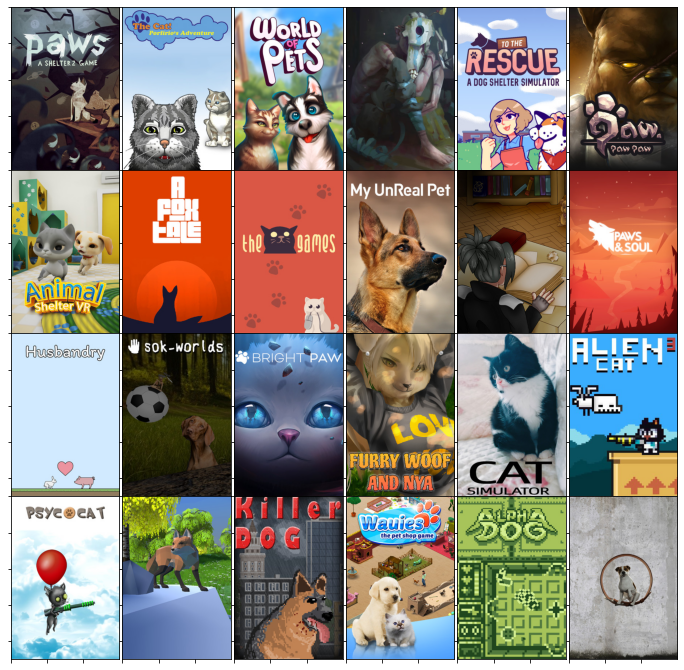

In [ ]:
text = "A dog plays with a cat"
ids = match_text(text_query=text, index=index_knn)

Query: A woman with blue hair wears glasses


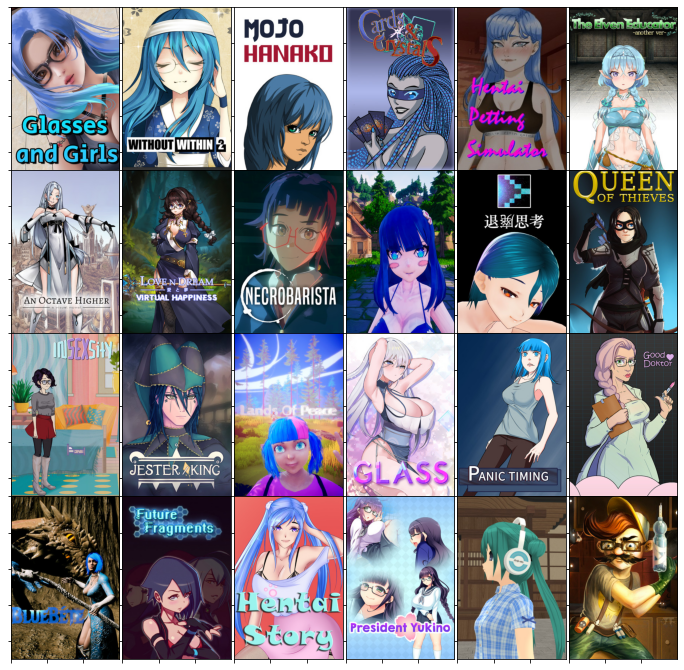

In [ ]:
text = "A woman with blue hair wears glasses"
ids = match_text(text_query=text, index=index_knn)

Query: A nerdy white man looks at a screen


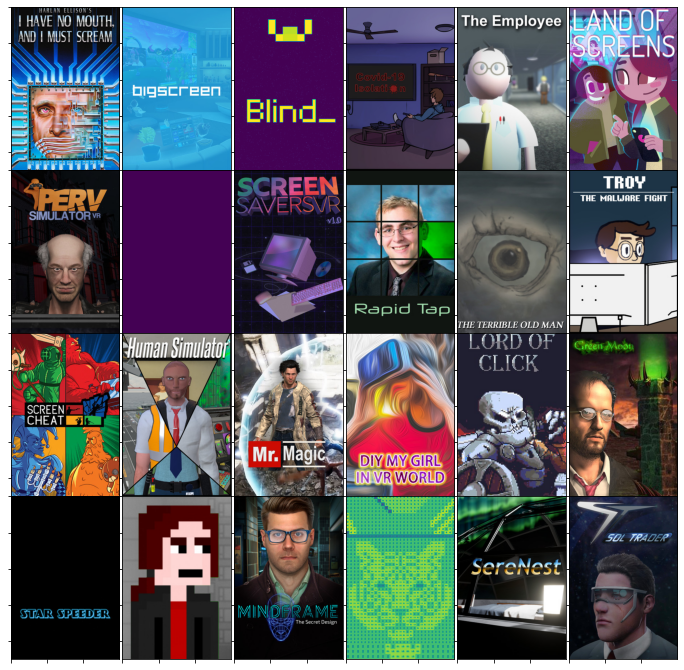

In [ ]:
text = "A nerdy white man looks at a screen"
ids = match_text(text_query=text, index=index_knn)

Query: A cat smiles at a person


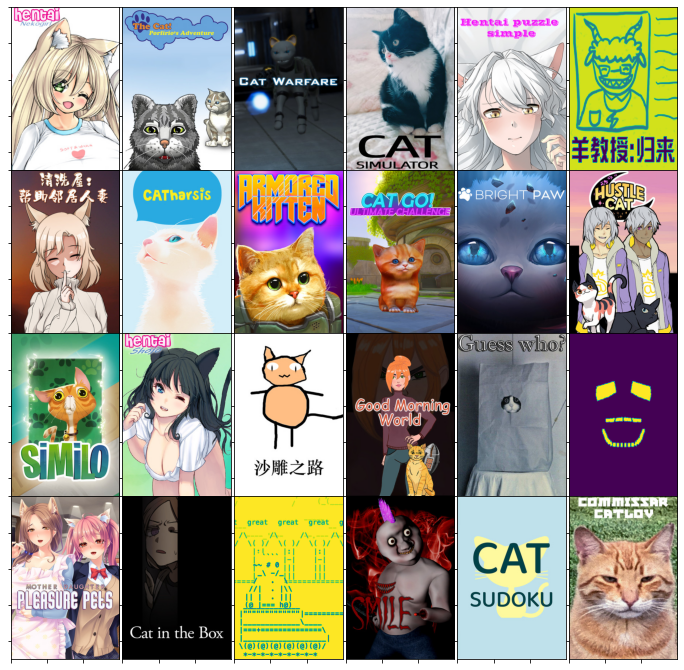

In [ ]:
text = "A cat smiles at a person"
ids = match_text(text_query=text, index=index_knn)

Query: A woman with blonde hair wears tight shorts


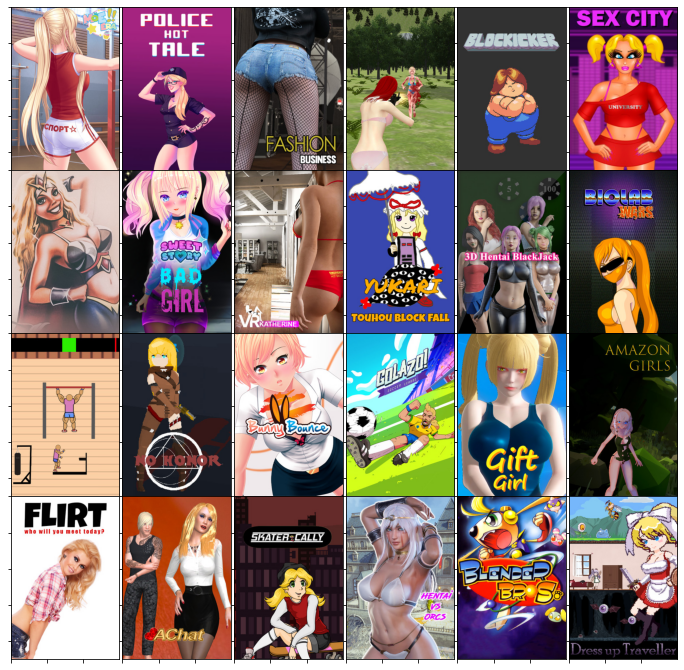

In [ ]:
text = "A woman with blonde hair wears tight shorts"
ids = match_text(text_query=text, index=index_knn)

## Reverse image search (using image queries)

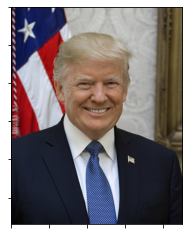

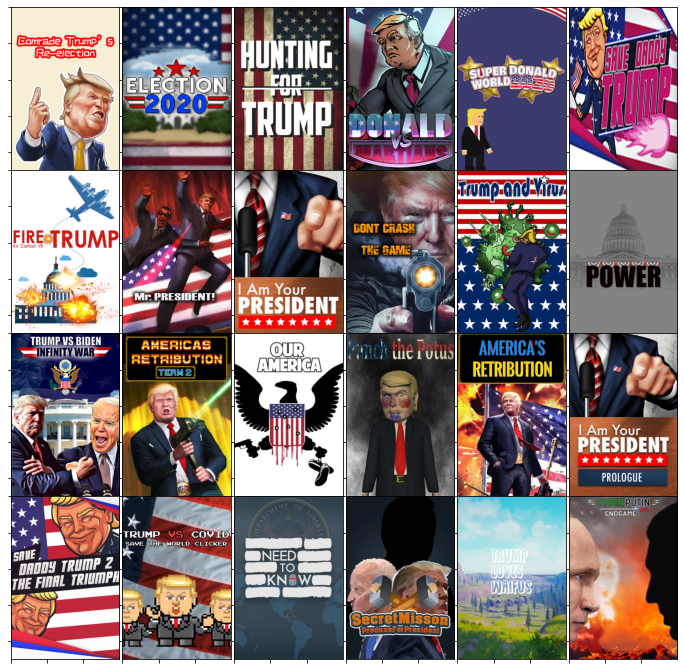

In [ ]:
image = load_image_from_url(url='https://upload.wikimedia.org/wikipedia/commons/5/56/Donald_Trump_official_portrait.jpg')
ids = match_image(image_query=image, index=index_knn)

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  1437  100  1437    0     0  14814      0 --:--:-- --:--:-- --:--:-- 14814


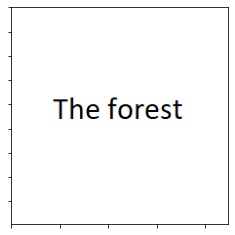

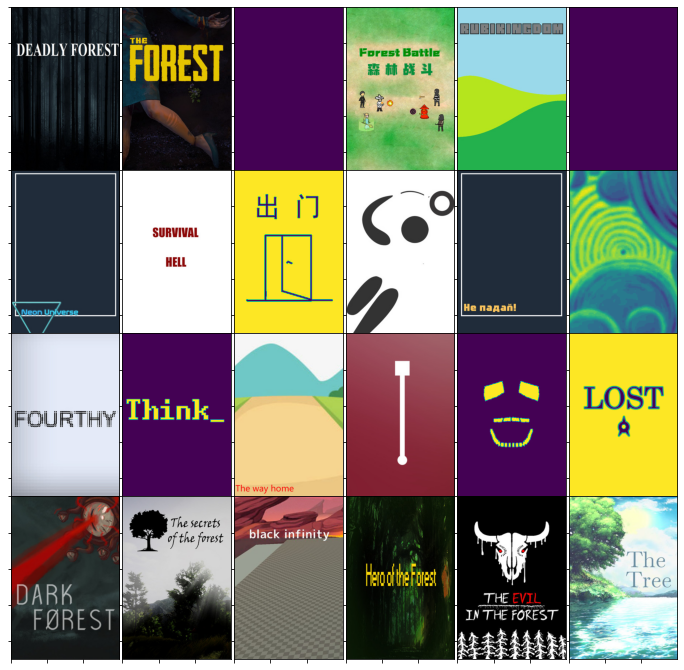

In [ ]:
fname = 'image_query.png'
!curl -O https://raw.githubusercontent.com/wiki/woctezuma/steam-image-search/img/{fname}
image = load_image_from_disk(fname=fname)

ids = match_image(image_query=image, index=index_knn)